In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("Libraries imported")

Libraries imported


In [12]:
data = pd.read_csv('iris.csv', encoding='utf-8-sig')

print("Shape:", data.shape)
print()
print("First 5 rows:")
data.head()

Shape: (150, 5)

First 5 rows:


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [13]:
print("Column names:", list(data.columns))
print()
print("Class distribution:")
print(data['variety'].value_counts())
print()
print("Missing values:", data.isnull().sum().sum())
print()
print("Statistical summary:")
data.describe()

Column names: ['sepal.length', 'sepal.width', 'petal.length', 'petal.width', 'variety']

Class distribution:
variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

Missing values: 0

Statistical summary:


,sepal.length,sepal.width,petal.length,petal.width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


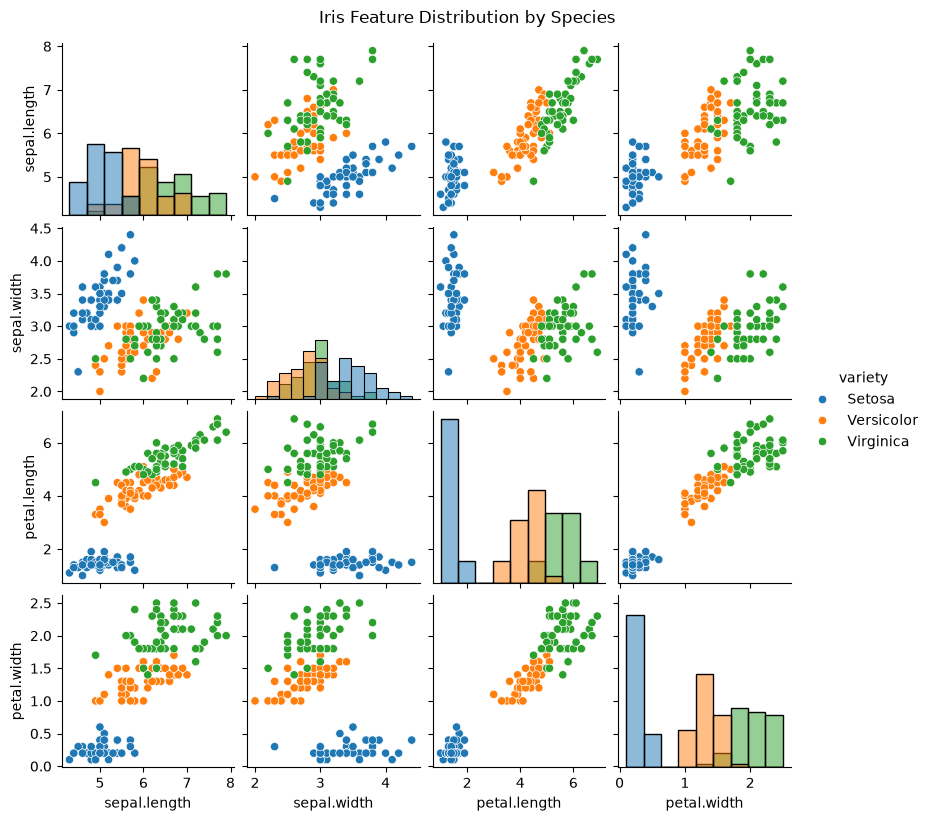

In [14]:
sns.pairplot(data, hue='variety', diag_kind='hist', height=2)
plt.suptitle("Iris Feature Distribution by Species", y=1.02)
plt.show()

In [15]:
X = data.drop('variety', axis=1)
y = data['variety']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", y.unique())

X shape: (150, 4)
y shape: (150,)
Classes: <ArrowStringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str


In [16]:
X = data.drop('variety', axis=1)
y = data['variety']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", y.unique())

X shape: (150, 4)
y shape: (150,)
Classes: <ArrowStringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print()
print("Train classes:")
print(y_train.value_counts())
print()
print("Test classes:")
print(y_test.value_counts())

Train size: (120, 4)
Test size: (30, 4)

Train classes:
variety
Setosa        40
Virginica     40
Versicolor    40
Name: count, dtype: int64

Test classes:
variety
Setosa        10
Virginica     10
Versicolor    10
Name: count, dtype: int64


In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled")
print("Train mean:", X_train_scaled.mean(axis=0).round(3))
print("Train std:", X_train_scaled.std(axis=0).round(3))

Scaled
Train mean: [-0.  0.  0.  0.]
Train std: [1. 1. 1. 1.]


In [19]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("KNN with k=5 trained and predicted")

KNN with k=5 trained and predicted


In [20]:
acc = accuracy_score(y_test, y_pred)
print(f"KNN k=5 Accuracy: {acc * 100:.2f} percent")

KNN k=5 Accuracy: 93.33 percent


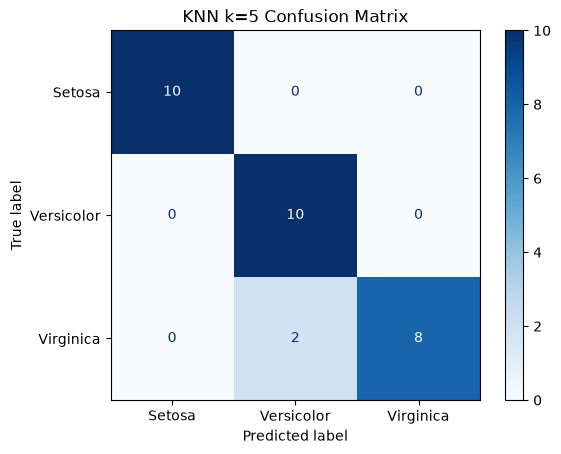

In [21]:
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
disp.plot(cmap='Blues')
plt.title("KNN k=5 Confusion Matrix")
plt.show()

In [22]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



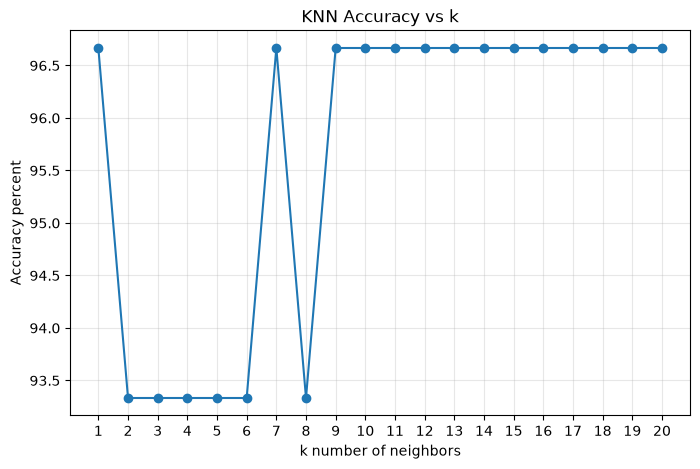

Best k = 1
Accuracy = 96.67 percent


In [23]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, pred))

plt.figure(figsize=(8, 5))
plt.plot(k_values, [a * 100 for a in accuracies], marker='o', linestyle='-')
plt.xlabel("k number of neighbors")
plt.ylabel("Accuracy percent")
plt.title("KNN Accuracy vs k")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

best_k = k_values[int(np.argmax(accuracies))]
print(f"Best k = {best_k}")
print(f"Accuracy = {max(accuracies) * 100:.2f} percent")

In [24]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_scaled, y_train)
y_pred_best = knn_best.predict(X_test_scaled)

print(f"Final KNN with k={best_k}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best) * 100:.2f} percent")
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_best))

Final KNN with k=1
Accuracy: 96.67 percent

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.91      1.00      0.95        10
   Virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [26]:
import warnings
warnings.filterwarnings("ignore")

test_flowers = [
    [5.0, 3.4, 1.5, 0.2],
    [6.0, 2.9, 4.5, 1.5],
    [6.5, 3.0, 5.8, 2.2],
    [4.5, 2.3, 1.3, 0.3],
    [7.7, 3.8, 6.7, 2.2],
]

print(f"{'Sepal L':>8} {'Sepal W':>8} {'Petal L':>8} {'Petal W':>8}   {'Prediction':<12} Confidence")
print("-" * 70)

for flower in test_flowers:
    f_df = pd.DataFrame([flower], columns=X.columns)
    f_scaled = scaler.transform(f_df)
    pred = knn_best.predict(f_scaled)[0]
    prob = knn_best.predict_proba(f_scaled)[0].max()
    print(f"{flower[0]:>8} {flower[1]:>8} {flower[2]:>8} {flower[3]:>8}   {pred:<12} {prob*100:.2f} percent")

 Sepal L  Sepal W  Petal L  Petal W   Prediction   Confidence
----------------------------------------------------------------------
     5.0      3.4      1.5      0.2   Setosa       100.00 percent
     6.0      2.9      4.5      1.5   Versicolor   100.00 percent
     6.5      3.0      5.8      2.2   Virginica    100.00 percent
     4.5      2.3      1.3      0.3   Setosa       100.00 percent
     7.7      3.8      6.7      2.2   Virginica    100.00 percent
